# Tuần 9 — M3: M2 tinh chỉnh tiếp với dữ liệu người đội mũ thường (Open Images, SH17)

Trên tập ngoài miền (ảnh công trường Việt Nam), M2 coi mũ thường (nón lá, mũ vải, mũ lưỡi trai, mũ cối) là mũ bảo hộ và
nhận nhầm nhiều người đầu trần chụp gần là có đội mũ (chênh mAP@0.5 với tập test 0,431 > 0,15). M3 huấn luyện tiếp từ
`best.pt` của M2, **giữ nguyên mọi siêu tham số của M2**, chỉ thêm dữ liệu vào tập train:

| Nguồn | Nội dung | Script |
|---|---|---|
| SHEL5K (như M2) | công trường, người nhỏ | `scripts/prepare_dataset.py` |
| Open Images V7 | người đội mũ thường (Hat, Sun hat, Fedora, Cowboy hat, Sombrero) → `person_no_helmet` | `scripts/prepare_openimages.py` |
| SH17 | công nhân sản xuất chụp gần, đa số không đội mũ bảo hộ | `scripts/prepare_sh17.py` |

Tập val dùng để chọn `best.pt` là val của cả ba nguồn (chọn mô hình tốt chung, không chỉ trên SHEL5K); sau huấn luyện đánh
giá riêng từng nguồn. Tập ngoài miền **không** nằm trong dữ liệu huấn luyện hay val. Đây là phần cải tiến ngoài đề cương.

**Cách chạy (VS Code + tiện ích Google Colab, tài khoản Colab Pro):**
1. Tải `data/M3_extra.zip` (ở máy local) lên Google Drive vào thư mục `MyDrive/DATN/data/` của **đúng tài khoản Colab Pro**.
   Trong `MyDrive/DATN/runs/M2_yolo26n/weights/` của tài khoản này phải có `best.pt` của M2 (đã có từ tuần 7).
2. `Select Kernel` → `Colab` → `New Colab Server` → `GPU` → chọn **A100** (hoặc L4 nếu hết A100).
3. `Run All`. Ô gắn Google Drive: bấm `Connect to Google Drive`, cấp quyền xong trong trình duyệt rồi mới bấm `Continue`.
4. Nếu Colab bị ngắt: chọn lại kernel Colab và `Run All` lần nữa — notebook tự huấn luyện tiếp từ `last.pt` trên Drive.
5. Xong: tải `M3_yolo26n_extra_results.zip` (trong `MyDrive/DATN/runs`) về, giải nén vào thư mục `runs/` của repo.

**Theo dõi tiến độ:** mỗi epoch in một dòng bắt đầu bằng `[M3_yolo26n_extra]`.

In [1]:
# Cấu hình: giống M2, thêm dữ liệu và điểm bắt đầu là best.pt của M2
from pathlib import Path

RUN_NAME = "M3_yolo26n_extra"
BASE_RUN = "M2_yolo26n"  # huấn luyện tiếp từ MyDrive/DATN/runs/M2_yolo26n/weights/best.pt
# siêu tham số của M2; optimizer, lr0 ghi rõ vì optimizer=auto đổi sang SGD khi > 10.000 vòng lặp (M2: AdamW, lr 0,001)
HYP = {"cls_pw": 0.5, "scale": (0.3, 1.5), "hsv_v": 0.6, "optimizer": "AdamW", "lr0": 0.001}
EPOCHS, IMGSZ, BATCH = 50, 800, 16
PRIORITY = "person_no_helmet"  # lớp vi phạm, mục tiêu Recall ≥ 0,80
NAMES = ["helmet", "head", "head_with_helmet", "person_with_helmet", "person_no_helmet", "face"]

ROOT = Path("/content")
DATA_DIR = ROOT / "SHEL5K_processed"
DATA_YAML = DATA_DIR / "data.yaml"
ZIP_ID = "1yJzRS_zbwqPiHM0P5JmBkGXkkih-2xdA"  # data/SHEL5K_processed.zip trên Google Drive (chia sẻ công khai)
ZIP_MD5 = "40f58cafcb67aac310a6a5ee358178d8"
EXPECTED = {"train": (3522, 46550), "val": (751, 9955), "test": (727, 9929)}  # (ảnh, hộp) theo reports/preprocessing/summary.json
EXTRA_DIR = ROOT / "M3_extra"
EXTRA_MD5 = "7b2190ff6a7161a46647c06b1adb02c5"  # data/M3_extra.zip (scripts/pack_m3_extra.py)
EXTRA_EXPECTED = {'openimages': {'train': (771, 3380), 'val': (64, 214)}, 'sh17': {'train': (4491, 20272), 'val': (1127, 5165)}}  # (ảnh, hộp) theo reports/extra/pack_output.txt

## 1. Kiểm tra GPU và cài thư viện

Giữ nguyên PyTorch có sẵn của Colab, chỉ cài Ultralytics đúng phiên bản dùng ở máy local.

In [2]:
import shutil, subprocess

assert shutil.which("nvidia-smi"), "Chưa có GPU: Select Kernel → Colab → New Colab Server → GPU → A100"
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout)

Tesla T4, 15360 MiB



In [3]:
%pip install -q ultralytics==8.4.164 gdown

## 2. Gắn Google Drive

Kết quả huấn luyện (trọng số mỗi epoch, `results.csv`, biểu đồ) được ghi thẳng vào `MyDrive/DATN/runs` để không mất khi Colab ngắt phiên.

In [4]:
from google.colab import drive

# Lỗi "Credentials propagation unsuccessful": chạy lại ô này, cấp quyền xong trong trình duyệt rồi mới bấm Continue
drive.mount(str(ROOT / "drive"))
PROJECT = ROOT / "drive/MyDrive/DATN/runs"
PROJECT.mkdir(parents=True, exist_ok=True)
print("Lưu kết quả vào:", PROJECT)

Mounted at /content/drive
Lưu kết quả vào: /content/drive/MyDrive/DATN/runs


## 3. Tải và kiểm tra dữ liệu

SHEL5K tải bằng `gdown` như M2; dữ liệu thêm chép từ `MyDrive/DATN/data/M3_extra.zip`. Cả hai kiểm tra MD5 với file tạo ở
máy local, rồi đếm lại số ảnh, file nhãn, hộp từng tập. Sau đó ghi `data_m3.yaml` (train, val của cả ba nguồn) và một tệp
yaml riêng cho từng nguồn để đánh giá riêng.

In [5]:
import hashlib, zipfile, yaml

def md5(path):
    with open(path, "rb") as f:
        return hashlib.file_digest(f, "md5").hexdigest()

def count(img_dir):
    imgs = [p for p in img_dir.glob("*") if p.suffix in (".png", ".jpg")]
    labels = list(Path(str(img_dir).replace("/images/", "/labels/")).glob("*.txt"))
    return len(imgs), len(labels), sum(len(p.read_text().splitlines()) for p in labels)

zip_path = ROOT / "SHEL5K_processed.zip"
if not DATA_YAML.exists():
    if not zip_path.exists():
        import gdown
        gdown.download(id=ZIP_ID, output=str(zip_path), quiet=False)
    assert md5(zip_path) == ZIP_MD5, f"File zip SHEL5K khác bản gốc: xóa {zip_path} rồi chạy lại ô này"
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(ROOT)
extra_zip = ROOT / "drive/MyDrive/DATN/data/M3_extra.zip"
if not EXTRA_DIR.exists():
    assert extra_zip.exists(), "Chưa có MyDrive/DATN/data/M3_extra.zip: tải file data/M3_extra.zip ở máy local lên Drive"
    assert md5(extra_zip) == EXTRA_MD5, "M3_extra.zip trên Drive khác bản local (tải lên chưa xong?): tải lại"
    with zipfile.ZipFile(extra_zip) as z:
        z.extractall(ROOT)

sources = {"shel5k": DATA_DIR} | {name: EXTRA_DIR / name for name in ("openimages", "sh17")}
for name, base in sources.items():
    for split, (n_img, n_box) in (EXPECTED if name == "shel5k" else EXTRA_EXPECTED[name]).items():
        got = count(base / "images" / split)
        print(f"{name:10s} {split:5s}: {got[0]} ảnh, {got[1]} file nhãn, {got[2]} hộp")
        assert got == (n_img, n_img, n_box), f"{name} {split} không khớp bản local"

def write_yaml(path, train, val):
    path.write_text(yaml.safe_dump({"train": [str(p) for p in train], "val": [str(p) for p in val],
                                    "nc": len(NAMES), "names": NAMES}, allow_unicode=True))
    return path

M3_YAML = write_yaml(ROOT / "data_m3.yaml", [b / "images/train" for b in sources.values()],
                     [b / "images/val" for b in sources.values()])
VAL_YAMLS = {name: write_yaml(ROOT / f"val_{name}.yaml", [b / "images/train"], [b / "images/val"])
             for name, b in sources.items()}
print(M3_YAML.read_text())

Downloading...
From (original): https://drive.google.com/uc?id=1yJzRS_zbwqPiHM0P5JmBkGXkkih-2xdA
From (redirected): https://drive.google.com/uc?id=1yJzRS_zbwqPiHM0P5JmBkGXkkih-2xdA&confirm=t&uuid=fcebb273-d6c8-4864-ae58-772f04f24f31
To: /content/SHEL5K_processed.zip
100%|██████████| 1.04G/1.04G [00:12<00:00, 80.7MB/s]


shel5k     train: 3522 ảnh, 3522 file nhãn, 46550 hộp
shel5k     val  : 751 ảnh, 751 file nhãn, 9955 hộp
shel5k     test : 727 ảnh, 727 file nhãn, 9929 hộp
openimages train: 771 ảnh, 771 file nhãn, 3380 hộp
openimages val  : 64 ảnh, 64 file nhãn, 214 hộp
sh17       train: 4491 ảnh, 4491 file nhãn, 20272 hộp
sh17       val  : 1127 ảnh, 1127 file nhãn, 5165 hộp
names:
- helmet
- head
- head_with_helmet
- person_with_helmet
- person_no_helmet
- face
nc: 6
train:
- /content/SHEL5K_processed/images/train
- /content/M3_extra/openimages/images/train
- /content/M3_extra/sh17/images/train
val:
- /content/SHEL5K_processed/images/val
- /content/M3_extra/openimages/images/val
- /content/M3_extra/sh17/images/val



## 4. Huấn luyện

Bắt đầu từ `best.pt` của M2 (trên Drive). Dòng `Class weights` trong log là trọng số lớp do `cls_pw` tạo ra, tính lại theo
dữ liệu train mới. Nếu trên Drive đã có `last.pt` của M3 thì huấn luyện tiếp (`resume=True`). Sau mỗi epoch, `log_epoch` in
một dòng tiến độ và ghi `epoch_log.csv` (Recall, AP@0.5 lớp `person_no_helmet` trên val chung của ba nguồn).

In [6]:
import csv, os
import torch
from ultralytics import YOLO

# shortcut: chế độ "không tương tác" của Ultralytics (chỉ ảnh hưởng thanh tiến độ) cập nhật 60 s/lần thay vì liên tục,
# để Auto Save của VS Code lưu được file notebook trong lúc huấn luyện; không ảnh hưởng kết quả huấn luyện
os.environ["GITHUB_ACTIONS"] = "true"

def log_epoch(trainer):
    epoch, total = trainer.epoch + 1, trainer.epochs
    if epoch > total:  # Ultralytics gọi thêm một lần sau khi đánh giá best.pt
        return
    pri = next(r for r in trainer.validator.metrics.summary() if r["Class"] == PRIORITY)
    log = trainer.save_dir / "epoch_log.csv"
    new = not log.exists()
    with open(log, "a", newline="") as f:
        w = csv.writer(f)
        if new:
            w.writerow(["epoch", "seconds", "recall_priority", "ap50_priority"])
        w.writerow([epoch, round(trainer.epoch_time, 1), pri["Box-R"], pri["mAP50"]])
    m = trainer.metrics
    losses = " ".join(f"{k.split('/')[1].removesuffix('_loss')} {v:.3f}"
                      for k, v in trainer.label_loss_items(trainer.tloss, prefix="train").items())
    print(f"[{RUN_NAME}] epoch {epoch}/{total} | {trainer.epoch_time:.0f} s, còn ~{trainer.epoch_time * (total - epoch) / 60:.0f} phút"
          f" | loss {losses} | mAP50 {m['metrics/mAP50(B)']:.3f} mAP50-95 {m['metrics/mAP50-95(B)']:.3f}"
          f" | R {PRIORITY} {pri['Box-R']:.3f}", flush=True)

run_dir = PROJECT / RUN_NAME
last = run_dir / "weights" / "last.pt"
# Ultralytics ghi epoch = -1 vào last.pt khi đã huấn luyện xong
finished = last.exists() and torch.load(last, map_location="cpu", weights_only=False)["epoch"] == -1
if finished:
    print(f"{RUN_NAME} đã huấn luyện xong, dùng lại kết quả trong {run_dir}")
else:
    if last.exists():
        print("Huấn luyện tiếp từ", last)
    base = PROJECT / BASE_RUN / "weights" / "best.pt"
    assert last.exists() or base.exists(), f"Không thấy {base}: chép thư mục runs/{BASE_RUN} của M2 lên Drive"
    model = YOLO(last if last.exists() else base)
    model.add_callback("on_fit_epoch_end", log_epoch)
    model.train(data=str(M3_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, **HYP,
                project=str(PROJECT), name=RUN_NAME, exist_ok=True, resume=last.exists())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Huấn luyện tiếp từ /content/drive/MyDrive/DATN/runs/M3_yolo26n_extra/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.198 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.164 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.5, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_m3.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_mo

## 5. Đường cong huấn luyện

Các hình đầu là mất mát trên tập train và val theo epoch; hình cuối là chỉ số trên tập val, đường nét đứt là mục tiêu (mAP@0.5 ≥ 0,85, Recall `person_no_helmet` ≥ 0,80).

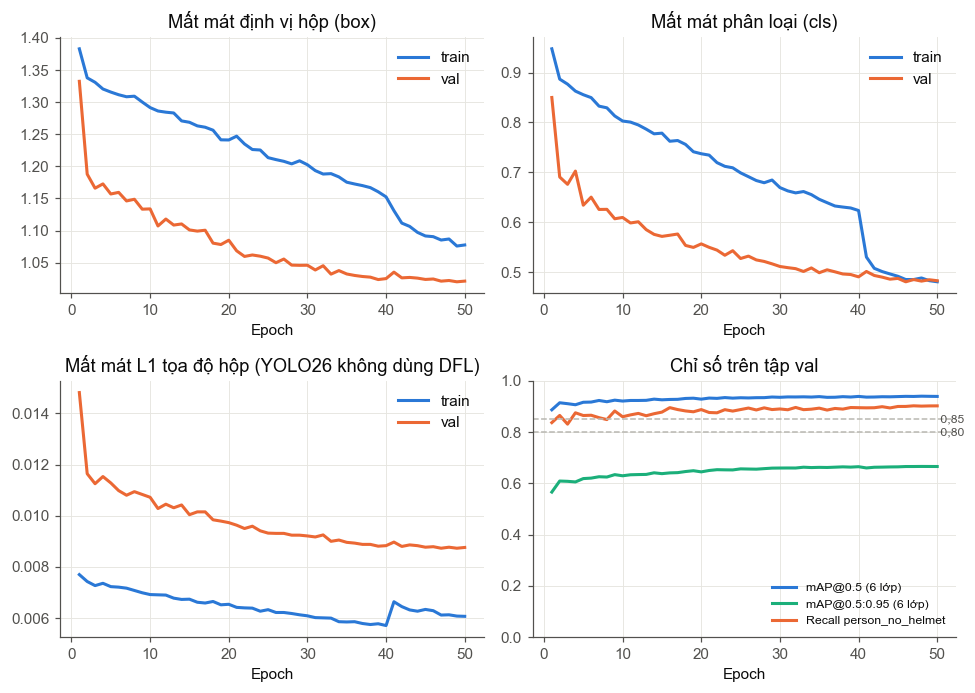

50 epoch, tổng thời gian huấn luyện 2.92 giờ


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

BLUE, ORANGE, AQUA, GRAY, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2", "#0b0b0b", "#52514e", "#e6e5e0"
fonts = {f.name for f in font_manager.fontManager.ttflist}
STYLE = {  # chỉ áp cho hình này, không ảnh hưởng hình Ultralytics vẽ ở các ô sau
    "font.family": next((f for f in ("Arial", "Liberation Sans") if f in fonts), "DejaVu Sans"), "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
}
TITLES = {"box_loss": "Mất mát định vị hộp (box)", "cls_loss": "Mất mát phân loại (cls)",
          "dfl_loss": "Mất mát phân phối biên (DFL)", "l1_loss": "Mất mát L1 tọa độ hộp (YOLO26 không dùng DFL)"}

res = pd.read_csv(run_dir / "results.csv").drop_duplicates("epoch", keep="last")  # epoch chạy lại khi resume
log = pd.read_csv(run_dir / "epoch_log.csv").drop_duplicates("epoch", keep="last")
loss_names = [c.split("/")[1] for c in res.columns if c.startswith("train/")]

with plt.rc_context(STYLE):
    rows = len(loss_names) // 2 + 1  # các ô mất mát + 1 ô chỉ số
    fig, axes = plt.subplots(rows, 2, figsize=(9, 3.2 * rows))
    axes = axes.ravel()
    for ax in axes[len(loss_names) + 1:]:
        ax.remove()
    for ax, name in zip(axes, loss_names):
        ax.plot(res["epoch"], res[f"train/{name}"], color=BLUE, lw=2, label="train")
        ax.plot(res["epoch"], res[f"val/{name}"], color=ORANGE, lw=2, label="val")
        ax.set(title=TITLES.get(name, name), xlabel="Epoch")
        ax.legend(frameon=False)
    ax = axes[len(loss_names)]
    ax.plot(res["epoch"], res["metrics/mAP50(B)"], color=BLUE, lw=2, label="mAP@0.5 (6 lớp)")
    ax.plot(res["epoch"], res["metrics/mAP50-95(B)"], color=AQUA, lw=2, label="mAP@0.5:0.95 (6 lớp)")
    ax.plot(log["epoch"], log["recall_priority"], color=ORANGE, lw=2, label=f"Recall {PRIORITY}")
    for y in (0.85, 0.80):
        ax.axhline(y, color=GRAY, lw=1, ls="--")
        ax.text(res["epoch"].max(), y, f" {y:.2f}".replace(".", ","), va="center", fontsize=8, color=INK2)
    ax.set(title="Chỉ số trên tập val", xlabel="Epoch", ylim=(0, 1))
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    fig.tight_layout()
    fig.savefig(run_dir / "fig_curves.png")
    plt.show()
print(f"{len(res)} epoch, tổng thời gian huấn luyện {log['seconds'].sum() / 3600:.2f} giờ")

## 6. Đánh giá `best.pt` trên val của từng nguồn

So với M2 trên val SHEL5K (mAP@0.5 0,912, Recall `person_no_helmet` 0,794 ở ngưỡng chung). Tập test SHEL5K và hai tập ngoài
miền đánh giá ở máy local sau khi tải kết quả về (cùng script như M2), không dùng ở đây.

In [8]:
import json

best = YOLO(run_dir / "weights" / "best.pt")
results = {}
for name, data in VAL_YAMLS.items():
    val = best.val(data=str(data), split="val", imgsz=IMGSZ, batch=BATCH, plots=name == "shel5k",
                   project=str(run_dir), name=f"val_best_{name}", exist_ok=True, verbose=False)
    per_class = pd.DataFrame(val.summary()).set_index("Class")
    print(f"== {name}: mAP@0.5 {val.box.map50:.3f}, mAP@0.5:0.95 {val.box.map:.3f}")
    display(per_class[["Instances", "Box-P", "Box-R", "mAP50", "mAP50-95"]].round(3))
    results[name] = {"val": val.results_dict, "per_class": val.summary(), "speed_ms": val.speed}

with open(run_dir / "val_metrics.json", "w") as f:
    json.dump({"run": RUN_NAME, "base": BASE_RUN, "epochs": EPOCHS, "imgsz": IMGSZ, "batch": BATCH, "hyp": HYP,
               "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
               "train_hours": round(log["seconds"].sum() / 3600, 2), **results},
              f, ensure_ascii=False, indent=2, default=lambda o: o.item())

Ultralytics 8.4.164 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3789.4±1067.2 MB/s, size: 210.4 KB)
val: Scanning /content/SHEL5K_processed/labels/val... 751 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 751/751 1.3Kit/s 0.6s
val: New cache created: /content/SHEL5K_processed/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 3.5it/s 13.4s
                   all        751       9955      0.904      0.862      0.914      0.602
Speed: 1.7ms preprocess, 6.0ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/drive/MyDrive/DATN/runs/M3_yolo26n_extra/val_best_shel5k
== shel5k: mAP@0.5 0.914, mAP@0.5:0.95 0.602


,Instances,Box-P,Box-R,mAP50,mAP50-95
Class,,,,,
helmet,2329,0.947,0.897,0.945,0.621
head,813,0.931,0.850,0.914,0.587
head_with_helmet,2079,0.911,0.925,0.950,0.664
person_with_helmet,2078,0.890,0.893,0.931,0.697
person_no_helmet,750,0.861,0.817,0.879,0.653
face,1906,0.885,0.790,0.862,0.389


Ultralytics 8.4.164 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3386.0±1073.1 MB/s, size: 117.2 KB)
val: Scanning /content/M3_extra/openimages/labels/val... 64 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 64/64 1.9Kit/s 0.0s
val: New cache created: /content/M3_extra/openimages/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.9it/s 1.4s
                   all         64        214      0.834      0.918      0.925      0.668
Speed: 2.4ms preprocess, 7.1ms inference, 0.0ms loss, 2.2ms postprocess per image
== openimages: mAP@0.5 0.925, mAP@0.5:0.95 0.668


,Instances,Box-P,Box-R,mAP50,mAP50-95
Class,,,,,
head,71,0.685,0.845,0.815,0.423
person_no_helmet,71,0.949,0.986,0.991,0.874
face,72,0.869,0.923,0.969,0.706


Ultralytics 8.4.164 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2695.6±763.3 MB/s, size: 74.7 KB)
val: Scanning /content/M3_extra/sh17/labels/val... 1127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1127/1127 1.9Kit/s 0.6s
val: New cache created: /content/M3_extra/sh17/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 71/71 6.6it/s 10.8s
                   all       1127       5165       0.92      0.889      0.934      0.739
Speed: 1.0ms preprocess, 4.6ms inference, 0.0ms loss, 1.4ms postprocess per image
== sh17: mAP@0.5 0.934, mAP@0.5:0.95 0.739


,Instances,Box-P,Box-R,mAP50,mAP50-95
Class,,,,,
helmet,86,0.890,0.860,0.908,0.686
head,1711,0.979,0.937,0.974,0.757
head_with_helmet,86,0.870,0.860,0.897,0.745
person_with_helmet,86,0.846,0.837,0.890,0.739
person_no_helmet,1711,0.961,0.933,0.972,0.810
face,1485,0.974,0.906,0.964,0.699


## 7. Ma trận nhầm lẫn trên val SHEL5K (chuẩn hóa theo nhãn thật)

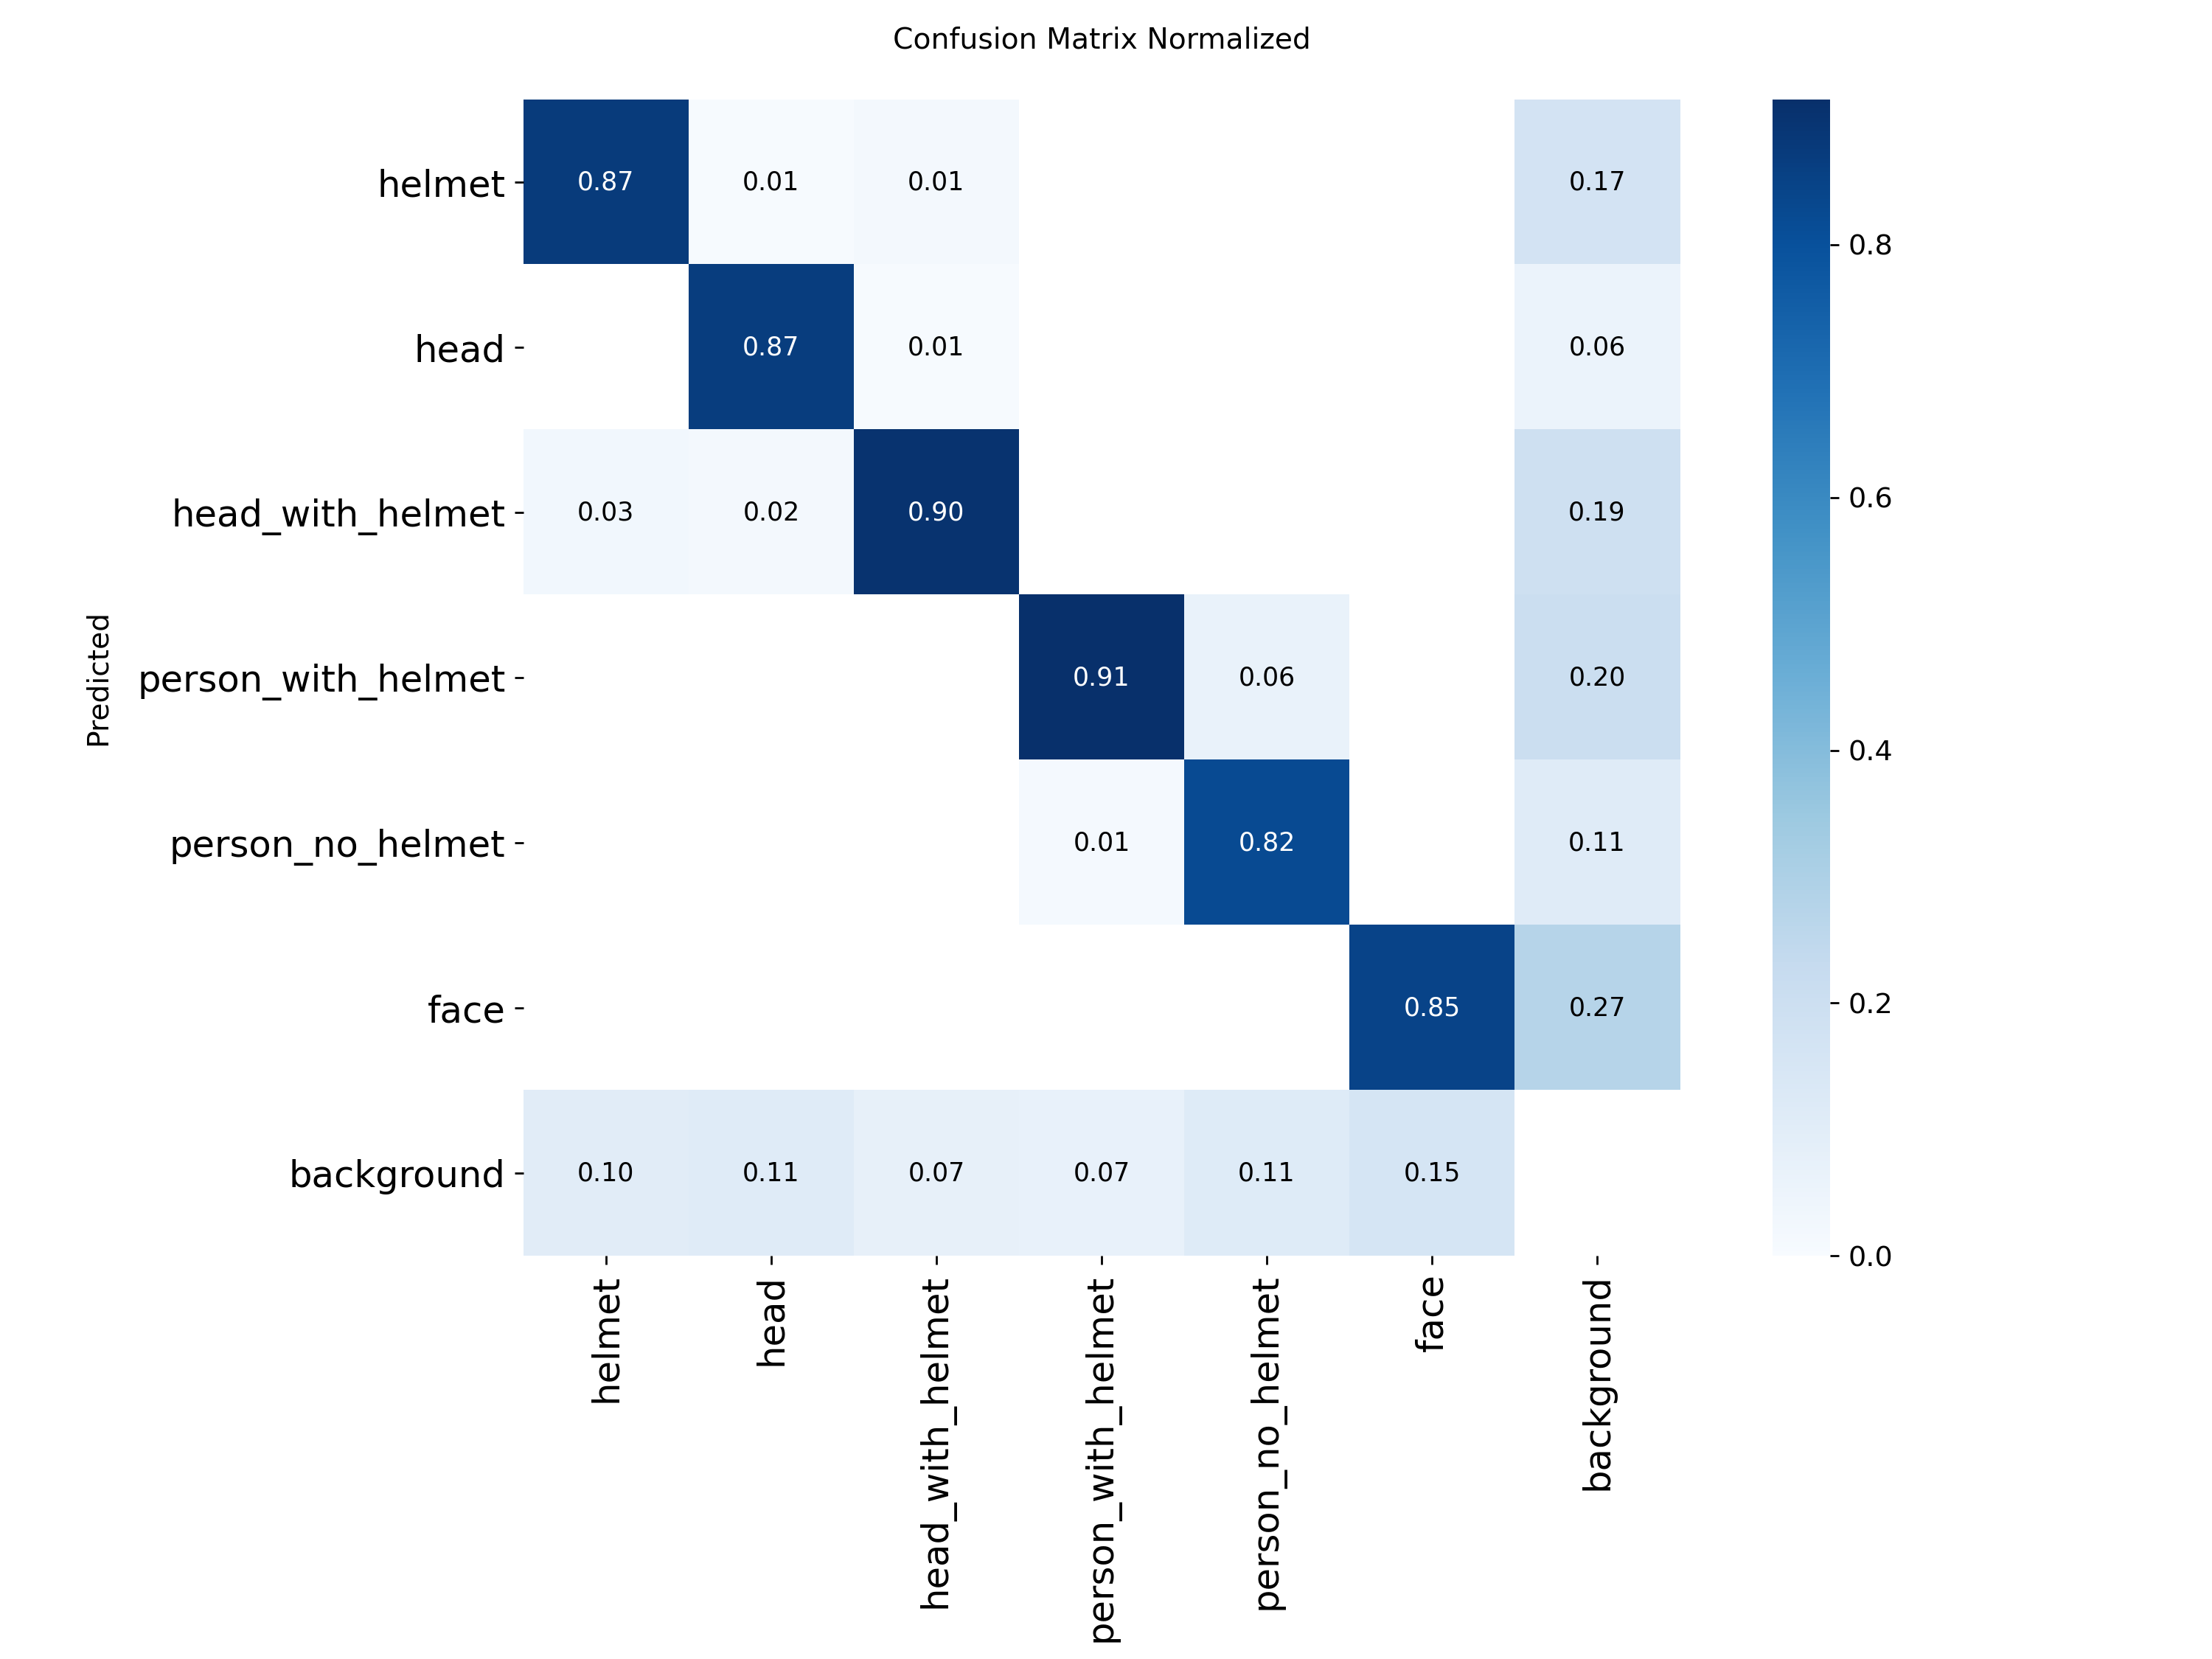

In [9]:
from IPython.display import Image

display(Image(filename=run_dir / "val_best_shel5k" / "confusion_matrix_normalized.png", width=700))

## 8. Đóng gói kết quả

Nén thư mục kết quả (bỏ `last.pt`, chỉ cần khi huấn luyện tiếp) thành `<RUN_NAME>_results.zip`, lưu ở `/content` và trên Drive.

In [10]:
import shutil

out = ROOT / f"{RUN_NAME}_results.zip"
with zipfile.ZipFile(out, "w") as z:
    for p in run_dir.rglob("*"):
        if p.is_file() and p.name != "last.pt":
            z.write(p, p.relative_to(PROJECT))
shutil.copy(out, PROJECT)
print(f"{out.name}: {out.stat().st_size / 1e6:.1f} MB, có ở {ROOT} và {PROJECT}")

M3_yolo26n_extra_results.zip: 18.2 MB, có ở /content và /content/drive/MyDrive/DATN/runs
